In [3]:
##plotting when was the best time to make jokes using visualization 2-defined function
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import scipy.stats as stats
from math import floor
import matplotlib.pyplot as plt
import plotly.express as px 
from pathlib import Path
from matplotlib.image import imread
import json
from datetime import datetime, timedelta
import nbimporter
import plotly.express as px
from scipy.ndimage import gaussian_filter1d
import plotly.graph_objects as go
# Get path to the project root: project/
PROJECT_ROOT = Path.cwd().parents[1]

# Add src/ to Python path
SRC_DIR = PROJECT_ROOT / "src"

sys.path.append(str(SRC_DIR))


#for theme
%run ../../docs/plotly_theme.ipynb


In [4]:

FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'data_cleaned'
IMG_DIR = DATA_DIR / 'images'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("SRC DIR     :" , SRC_DIR)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)

Project path setup:
PROJECT_ROOT:   c:\Users\hanna\ADA\ada-2025-project-json-derulo
SRC DIR     : c:\Users\hanna\ADA\ada-2025-project-json-derulo\src
FIGURES_DIR:    c:\Users\hanna\ADA\ada-2025-project-json-derulo\figures

DATA_DIR:       c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest
JSON_DIR:       c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\contests.json
CSV_DIR:        c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data
CSV_CLEAN_DIR:  c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned
IMG_DIR:        c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\images


In [6]:
def plot_number_of_captions_vs_contests(folder_path,image_path):
    folder_path=str(folder_path)
    contest_counts = {} #intialise caption number at 0
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Folder not found: {folder_path}") #missing contests
    for contest_num in range(510, 896):
        filename = f"{contest_num}_cleaned.csv" #added _cleaned to make it work in new dataset
        file_path = os.path.join(folder_path, filename)
        if os.path.exists(file_path):
            try:
                df = pd.read_csv(file_path)
                contest_counts[contest_num] = len(df) #to get the length of the file = number of captions per contest
            except Exception as e:
                print(f"Error reading {filename}: {e}")
        else:
            print(f"File not found: {filename}")

    # Turning them into Dataframes
    counts_df = pd.DataFrame(list(contest_counts.items()), columns=["Contest", "Num_Captions"])
    counts_df = counts_df.sort_values(by="Num_Captions", ascending=False) #ordered list of the contest with their corresponding number of captions

    # printing the gist of the top and least populars
    print("\nTop 5 most popular contests:")
    print(counts_df.head())

    print("\nTop 5 least popular contests:")
    print(counts_df.tail())

    # Defining the top and least popular
    most_popular = counts_df.iloc[0]
    least_popular = counts_df.iloc[-1]

    print(f"\nMost popular contest: #{most_popular['Contest']} with {most_popular['Num_Captions']} captions.")
    print(f"Least popular contest: #{least_popular['Contest']} with {least_popular['Num_Captions']} captions.")

    # Visualizing
    plt.figure(figsize=(10,5))
    plt.scatter(counts_df["Contest"], counts_df["Num_Captions"], marker='o', linestyle='-')
    # Highlight most & least popular on the scatter plot
    plt.scatter(most_popular["Contest"], most_popular["Num_Captions"], color='green', s=100, label='Most popular')
    plt.scatter(least_popular["Contest"], least_popular["Num_Captions"], color='red', s=100, label='Least popular')

    plt.annotate(f"{int(most_popular['Contest'])}",
                xy=(most_popular['Contest'], most_popular['Num_Captions']),
                xytext=(most_popular['Contest'], most_popular['Num_Captions'] + 100),
                arrowprops=dict(facecolor='green', arrowstyle='->'),
                fontsize=10)

    plt.annotate(f"{int(least_popular['Contest'])}",
                xy=(least_popular['Contest'], least_popular['Num_Captions']),
                xytext=(least_popular['Contest'], least_popular['Num_Captions'] - 100),
                arrowprops=dict(facecolor='red', arrowstyle='->'),
                fontsize=10)
    plt.title("Number of Captions per Contest")
    plt.xlabel("Contest Number")
    plt.ylabel("Number of Captions")
    plt.grid(True)
    plt.show()

In [7]:
def add_contest_dates(df):
    """
    Adds publish and vote dates for each contest based on weekly frequency.
    Contest 510 is assumed to be published on 22 Feb 2016.
    """

    base_publish = datetime.strptime('2016.02.22', "%Y.%m.%d")

    publish_dates = []
    vote_dates = []

    for i in range(len(df)):
        contest_id = df['contest_id'].iloc[i]
        diff = int(contest_id) - 510

        publish_date = base_publish + timedelta(days=diff * 7)
        vote_date = publish_date + timedelta(days=7)

        # Ensure metadata is a dictionary
        if df.at[i, 'metadata'] is None:
            df.at[i, 'metadata'] = {}

        # Now safe to assign
        df.at[i, 'metadata']['contest_day_publish'] = publish_date
        df.at[i, 'metadata']['contest_day_votes'] = vote_date

        publish_dates.append(publish_date)
        vote_dates.append(vote_date)

    df['contest_day_publish'] = publish_dates
    df['contest_day_votes'] = vote_dates

    return df

File not found: 525_cleaned.csv
File not found: 540_cleaned.csv

Top 5 most popular contests:
     Contest  Num_Captions
204      716         15148
232      744         12148
228      740         10934
241      753         10863
249      761         10594

Top 5 least popular contests:
     Contest  Num_Captions
86       598          2919
124      636          2886
324      836          1974
322      834          1429
323      835          1053

Most popular contest: #716 with 15148 captions.
Least popular contest: #835 with 1053 captions.


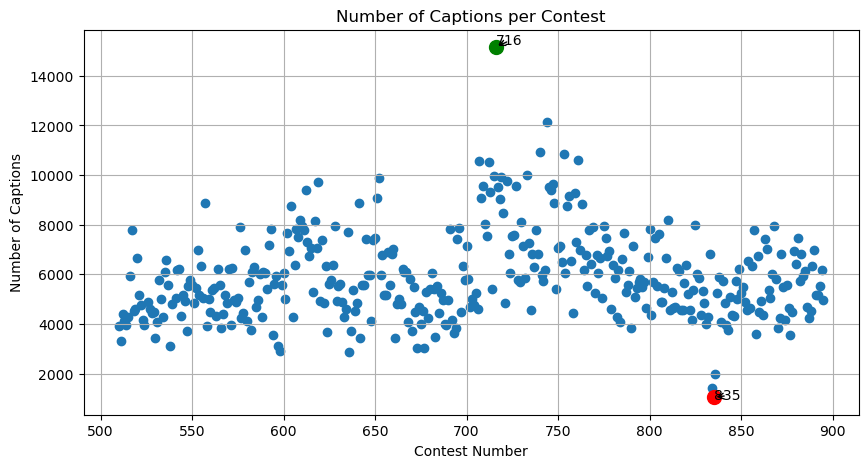

In [8]:
plot_number_of_captions_vs_contests(CSV_CLEAN_DIR, IMG_DIR)
#C:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned

In [6]:
contest_no_dates = pd.read_json(JSON_DIR)
contest_no_dates.head()



,contest_id,image,data,metadata
0,510,images/510.jpg,data/510.csv,"{'num_captions': 3905, 'num_votes': 41185, 'im..."
1,511,images/511.jpg,data/511.csv,"{'num_captions': 3325, 'num_votes': 28205, 'im..."
2,512,images/512.jpg,data/512.csv,"{'num_captions': 4399, 'num_votes': 21574, 'im..."
3,513,images/513.jpg,data/513.csv,"{'num_captions': 4141, 'num_votes': 16894, 'im..."
4,514,images/514.jpg,data/514.csv,"{'num_captions': 3951, 'num_votes': 95790, 'im..."


In [7]:
contest_with_dates = add_contest_dates(contest_no_dates)
contest_with_dates

,contest_id,image,data,metadata,contest_day_publish,contest_day_votes
0,510,images/510.jpg,data/510.csv,"{'num_captions': 3905, 'num_votes': 41185, 'im...",2016-02-22,2016-02-29
1,511,images/511.jpg,data/511.csv,"{'num_captions': 3325, 'num_votes': 28205, 'im...",2016-02-29,2016-03-07
2,512,images/512.jpg,data/512.csv,"{'num_captions': 4399, 'num_votes': 21574, 'im...",2016-03-07,2016-03-14
3,513,images/513.jpg,data/513.csv,"{'num_captions': 4141, 'num_votes': 16894, 'im...",2016-03-14,2016-03-21
4,514,images/514.jpg,data/514.csv,"{'num_captions': 3951, 'num_votes': 95790, 'im...",2016-03-21,2016-03-28
...,...,...,...,...,...,...
379,891,images/891.jpg,data/891.csv,"{'contest_day_publish': 2023-06-12 00:00:00, '...",2023-06-12,2023-06-19
380,892,images/892.jpg,data/892.csv,"{'contest_day_publish': 2023-06-19 00:00:00, '...",2023-06-19,2023-06-26
381,893,images/893.jpg,data/893.csv,"{'contest_day_publish': 2023-06-26 00:00:00, '...",2023-06-26,2023-07-03
382,894,images/894.jpg,data/894.csv,"{'contest_day_publish': 2023-07-03 00:00:00, '...",2023-07-03,2023-07-10


In [2]:
def plot_captions_timeline(folder_path, contest_with_dates, sigma=3):
    folder_path = str(folder_path)
    contest_counts = {}

    # Count captions per contest
    for contest_num in range(510, 896):
        filename = f"{contest_num}_cleaned.csv"
        file_path = os.path.join(folder_path, filename)

        if os.path.exists(file_path):
            try:
                df = pd.read_csv(file_path)
                contest_counts[contest_num] = len(df)
            except Exception as e:
                print(f"Error reading {filename}: {e}")

    # Create DataFrame
    counts_df = pd.DataFrame(list(contest_counts.items()),
                             columns=["Contest", "Num_Captions"])

    # Merge with publish dates
    merged = counts_df.merge(
        contest_with_dates[['contest_id', 'contest_day_publish']],
        left_on='Contest',
        right_on='contest_id',
        how='inner'
    ).sort_values(by="contest_day_publish")

    # Gaussian smoothing
    merged["smooth"] = gaussian_filter1d(merged["Num_Captions"], sigma=sigma)

    # Plot time series
    plt.figure(figsize=(12, 6))
    plt.plot(merged["contest_day_publish"], merged["Num_Captions"], alpha=0.3, label="Raw")
    plt.plot(merged["contest_day_publish"], merged["smooth"], color='black', linewidth=2, label="Smoothed")
    plt.scatter(merged["contest_day_publish"], merged["Num_Captions"], alpha=0.5)

    plt.title("Timeline of Contest Popularity (Gaussian-Smoothed)")
    plt.xlabel("Publish Date")
    plt.ylabel("Number of Captions")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return merged

In [1]:
plot_captions_timeline(CSV_CLEAN_DIR, contest_with_dates)

NameError: name 'plot_captions_timeline' is not defined

NOW AS PLOTLY

In [14]:
def plot_captions_timeline_plotly(folder_path, contest_with_dates, sigma=10):
    folder_path = str(folder_path)
    contest_counts = {}

    # Count captions per contest
    for contest_num in range(510, 896):
        filename = f"{contest_num}_cleaned.csv"
        file_path = os.path.join(folder_path, filename)

        if os.path.exists(file_path):
            try:
                df = pd.read_csv(file_path)
                contest_counts[contest_num] = len(df)
            except Exception as e:
                print(f"Error reading {filename}: {e}")

    # Create DataFrame
    counts_df = pd.DataFrame(list(contest_counts.items()),
                             columns=["Contest", "Num_Captions"])

    # Merge with publish dates
    merged = counts_df.merge(
        contest_with_dates[['contest_id', 'contest_day_publish']],
        left_on='Contest',
        right_on='contest_id',
        how='inner'
    ).sort_values(by="contest_day_publish")

    # Gaussian smoothing
    merged["smooth"] = gaussian_filter1d(merged["Num_Captions"], sigma=sigma)

    # Build Plotly figure
    fig = go.Figure()

    # Raw scatter points
    fig.add_trace(go.Scatter(
        x=merged["contest_day_publish"],
        y=merged["Num_Captions"],
        mode='markers',
        name='Raw Counts',
        opacity=0.5,
        marker=dict(size=6),
        hovertemplate=
            "<b>Date</b>: %{x}<br>" +
            "<b>Captions</b>: %{y}<br>" +
            "<b>Contest</b>: %{customdata}<extra></extra>",
        customdata=merged["Contest"],
    ))

    # Raw line (light)
    fig.add_trace(go.Scatter(
        x=merged["contest_day_publish"],
        y=merged["Num_Captions"],
        mode='lines',
        line=dict(width=1, color='rgba(150,150,150,0.3)'),
        name='Raw Trend',
        hoverinfo='skip'
    ))

    # Smoothed Gaussian curve
    fig.add_trace(go.Scatter(
        x=merged["contest_day_publish"],
        y=merged["smooth"],
        mode='lines',
        line=dict(color='black', width=3),
        name=f"Gaussian Smooth (σ={sigma})",
        hovertemplate=
            "<b>Date</b>: %{x}<br>" +
            "<b>Smoothed</b>: %{y:.2f}<extra></extra>"
    ))

    # Layout
    fig.update_layout(
        title="Timeline of Contest Popularity with Gaussian Smoothing",
        xaxis_title="Publish Date",
        yaxis_title="Number of Captions",
        template="for_dummies",
        hovermode="x unified",
        width=800,
        height=600,
    )
    # Save interactive HTML file
    save_path = r"C:\Users\hanna\ADA\ada-2025-project-json-derulo\docs\plots\caption_timeline_plot.html"
    fig.write_html(save_path, include_plotlyjs="cdn")
    fig.show()

    return merged

In [15]:
plot_captions_timeline_plotly(CSV_CLEAN_DIR, contest_with_dates)

,Contest,Num_Captions,contest_id,contest_day_publish,smooth
0,510,3905,510,2016-02-22,4697
1,511,3325,511,2016-02-29,4699
2,512,4399,512,2016-03-07,4702
3,513,4141,513,2016-03-14,4708
4,514,3951,514,2016-03-21,4714
...,...,...,...,...,...
379,891,5159,891,2023-06-12,5596
380,892,5188,892,2023-06-19,5595
381,893,5513,893,2023-06-26,5595
382,894,6157,894,2023-07-03,5595


We can see clearly the peak due to the pandemic effect in the number of submitted caption.
More people were online

More free time

Massive spike in all digital engagement

Caption contests, puzzles, games all saw surges